In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("food_delivery_orders.csv")

In [3]:
df.head()

,order_id,order_date,city,cuisine,customer_age,customer_type,payment_method,order_value,discount_pct,distance_km,delivery_time_min,rating
0,1001,2025-01-03,Bangalore,North Indian,18,Returning,UPI,317,10,9.2,30,3.9
1,1002,2025-01-04,Bangalore,Fast Food,48,Returning,UPI,219,0,2.0,17,4.6
2,1003,2025-01-04,Mumbai,Biryani,19,Returning,Wallet,592,15,4.4,26,3.5
3,1004,2025-01-05,Hyderabad,Fast Food,18,Returning,Card,565,5,5.9,25,4.0
4,1005,2025-01-06,Bangalore,Biryani,38,Returning,UPI,465,15,8.5,35,3.1


In [6]:
df.dtypes

order_id                      int64
order_date           datetime64[us]
city                            str
cuisine                         str
customer_age                  int64
customer_type                   str
payment_method                  str
order_value                   int64
discount_pct                  int64
distance_km                 float64
delivery_time_min             int64
rating                      float64
dtype: object

In [5]:
df['order_date'] = pd.to_datetime(df['order_date'],format="%Y-%m-%d")

In [7]:
df['month'] = df['order_date'].dt.month

In [8]:
df.head()

,order_id,order_date,city,cuisine,customer_age,customer_type,payment_method,order_value,discount_pct,distance_km,delivery_time_min,rating,month
0,1001,2025-01-03,Bangalore,North Indian,18,Returning,UPI,317,10,9.2,30,3.9,1
1,1002,2025-01-04,Bangalore,Fast Food,48,Returning,UPI,219,0,2.0,17,4.6,1
2,1003,2025-01-04,Mumbai,Biryani,19,Returning,Wallet,592,15,4.4,26,3.5,1
3,1004,2025-01-05,Hyderabad,Fast Food,18,Returning,Card,565,5,5.9,25,4.0,1
4,1005,2025-01-06,Bangalore,Biryani,38,Returning,UPI,465,15,8.5,35,3.1,1


In [10]:
sr = df.groupby('month')['order_id'].count()

In [11]:
sr.index

Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int32', name='month')

In [12]:
sr.values

array([36, 38, 32, 26, 41, 37, 31, 50, 48, 49, 47, 65])

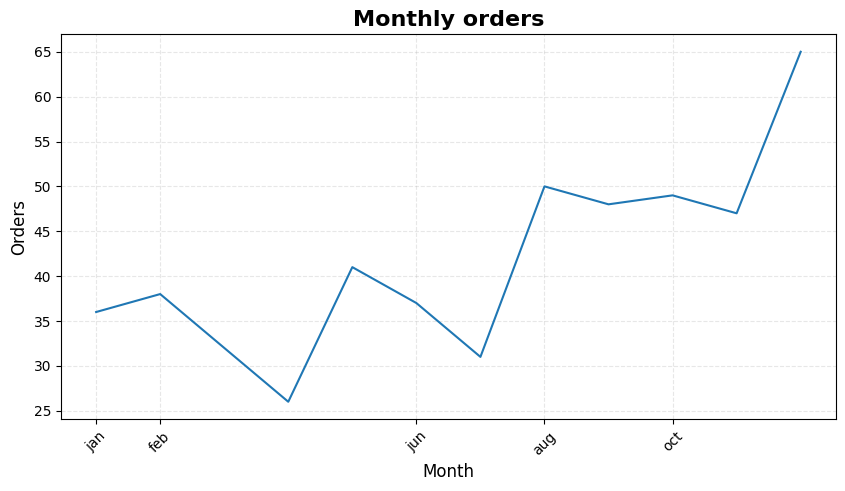

In [23]:
fig,axes = plt.subplots(figsize=(10,5))
axes.plot(sr.index,sr.values)
axes.set_title("Monthly orders",fontweight='bold',fontsize=16)
axes.set_xlabel("Month",fontsize=12)
axes.set_ylabel("Orders",fontsize=12)
axes.set_xticks([1,2,6,8,10])
axes.set_xticklabels(["jan","feb","jun","aug","oct"],rotation=45)
axes.grid(alpha=0.3,linestyle="--")
plt.show()

In [ ]:
orders_by_cuisine = df.groupby('cuisine')['order_id'].count()

In [27]:
orders_by_cuisine

cuisine
Biryani          91
Chinese          70
Desserts         49
Fast Food       115
North Indian    130
South Indian     45
Name: order_id, dtype: int64

In [25]:
orders_by_cuisine.index

Index(['Biryani', 'Chinese', 'Desserts', 'Fast Food', 'North Indian',
       'South Indian'],
      dtype='str', name='cuisine')

In [26]:
orders_by_cuisine.values

array([ 91,  70,  49, 115, 130,  45])

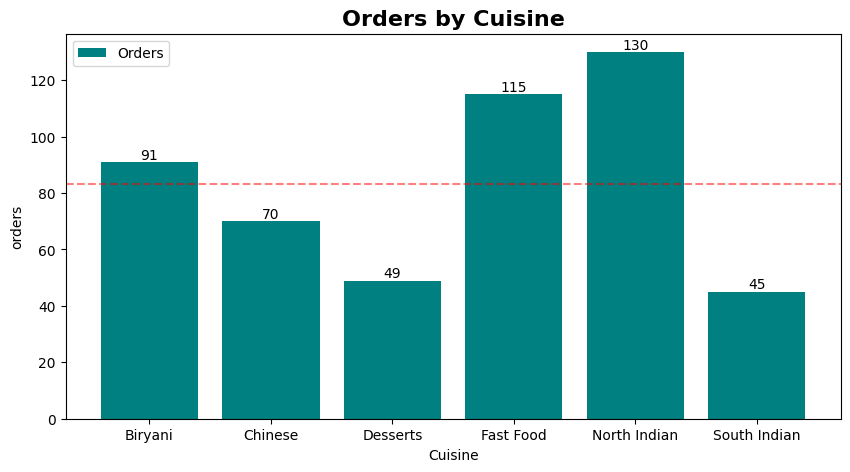

In [42]:
fig,axes = plt.subplots(figsize=(10,5))
avg = orders_by_cuisine.values.mean()
bar = axes.bar(orders_by_cuisine.index,orders_by_cuisine.values,color='teal',label="Orders")
axes.bar_label(bar)
axes.set_title("Orders by Cuisine",fontweight="bold",fontsize=16)
axes.set_xlabel("Cuisine")
axes.set_ylabel("orders")
axes.axhline(avg,color='red',linestyle="--",alpha=0.5)
axes.legend(loc='upper left')
plt.show()

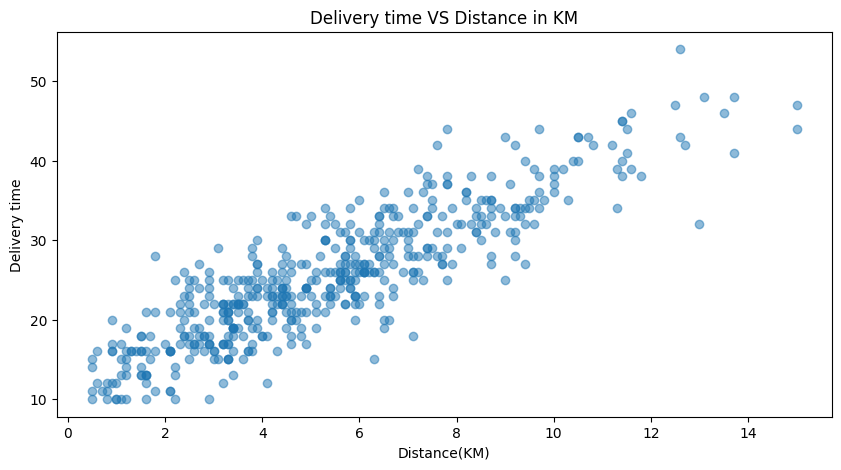

In [ ]:
fig,axes = plt.subplots(figsize=(10,5))

axes.scatter(df['distance_km'],df['delivery_time_min'],alpha=0.5)
axes.set_title("Delivery time VS Distance in KM",fontweight="bold",fontsize=16)
axes.set_ylabel("Delivery time")
axes.set_xlabel("Distance(KM)")
plt.show()

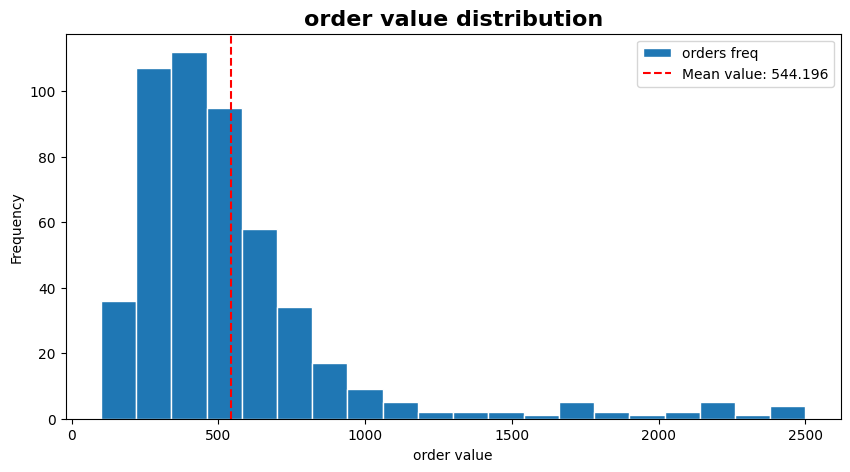

In [52]:
fig,axes = plt.subplots(figsize=(10,5))
axes.hist(df['order_value'],bins=20,edgecolor='white',label="orders freq")
avg = np.mean(df['order_value'])
axes.set_xlabel("order value")
axes.set_ylabel("Frequency")
axes.set_title("order value distribution",fontweight="bold",fontsize=16)
axes.axvline(avg,color="red",linestyle="--",label=f"Mean value: {avg}")
axes.legend()
plt.show()

[- -]
[- -]

0,0 - 0,1
1,0 - 1,1



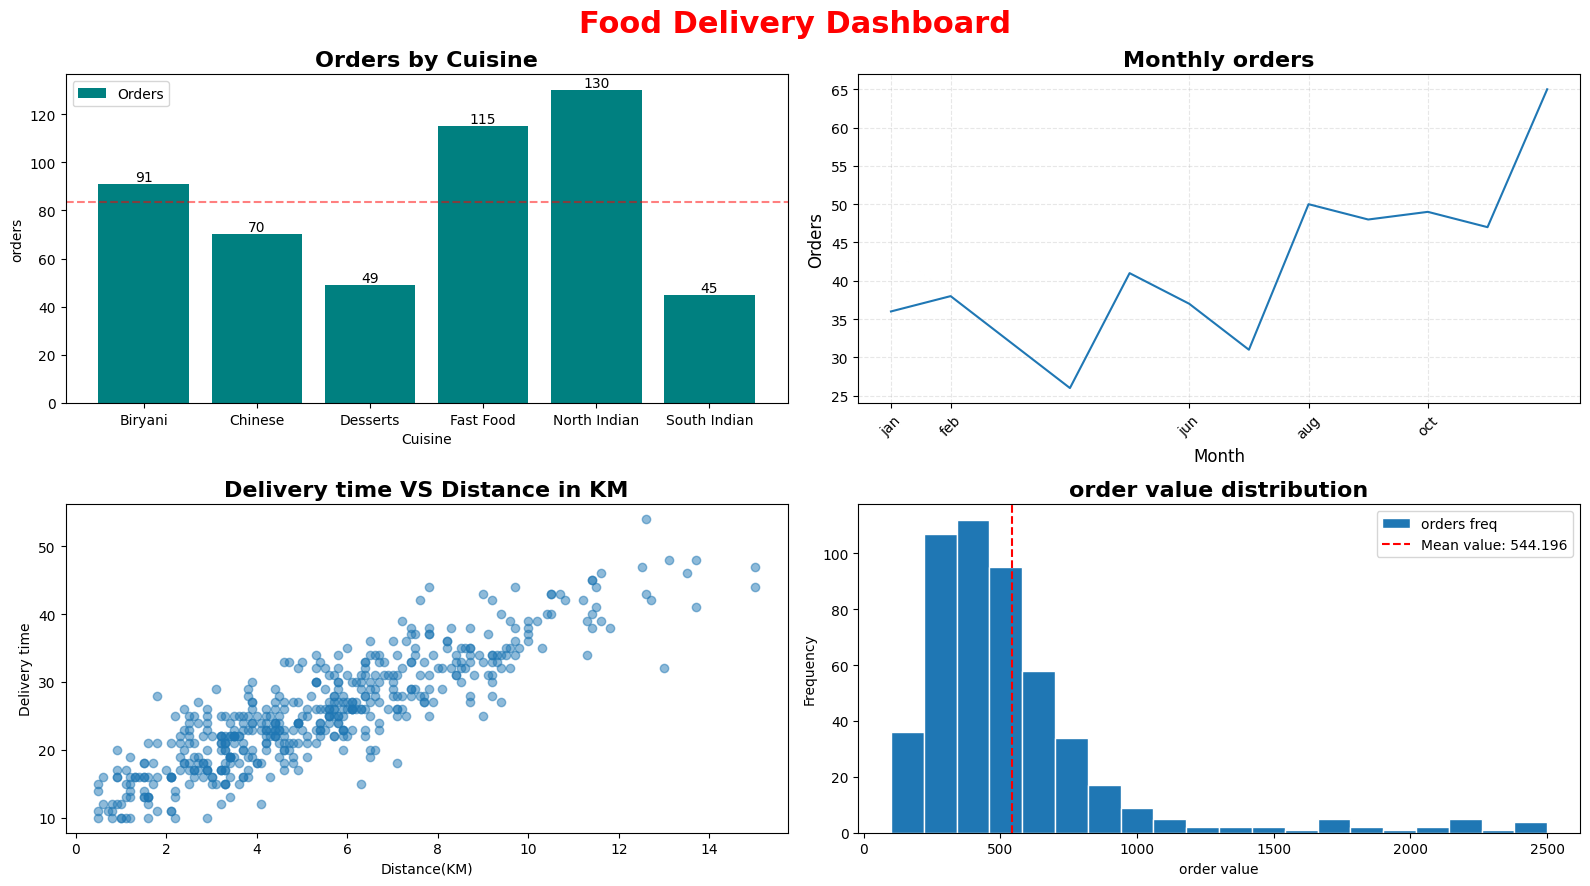

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(16,9))

avg = orders_by_cuisine.values.mean()
bar = axes[0,0].bar(orders_by_cuisine.index,orders_by_cuisine.values,color='teal',label="Orders")
axes[0,0].bar_label(bar)
axes[0,0].set_title("Orders by Cuisine",fontweight="bold",fontsize=16)
axes[0,0].set_xlabel("Cuisine")
axes[0,0].set_ylabel("orders")
axes[0,0].axhline(avg,color='red',linestyle="--",alpha=0.5)
axes[0,0].legend(loc='upper left')


axes[0,1].plot(sr.index,sr.values)
axes[0,1].set_title("Monthly orders",fontweight='bold',fontsize=16)
axes[0,1].set_xlabel("Month",fontsize=12)
axes[0,1].set_ylabel("Orders",fontsize=12)
axes[0,1].set_xticks([1,2,6,8,10])
axes[0,1].set_xticklabels(["jan","feb","jun","aug","oct"],rotation=45)
axes[0,1].grid(alpha=0.3,linestyle="--")


axes[1,0].scatter(df['distance_km'],df['delivery_time_min'],alpha=0.5)
axes[1,0].set_title("Delivery time VS Distance in KM",fontweight="bold",fontsize=16)
axes[1,0].set_ylabel("Delivery time")
axes[1,0].set_xlabel("Distance(KM)")


axes[1,1].hist(df['order_value'],bins=20,edgecolor='white',label="orders freq")
avg = np.mean(df['order_value'])
axes[1,1].set_xlabel("order value")
axes[1,1].set_ylabel("Frequency")
axes[1,1].set_title("order value distribution",fontweight="bold",fontsize=16)
axes[1,1].axvline(avg,color="red",linestyle="--",label=f"Mean value: {avg}")
axes[1,1].legend()

plt.suptitle("Food Delivery Dashboard",fontsize=22,fontweight='bold',color="red")
plt.tight_layout()
plt.savefig("dashboard.png")
plt.show()

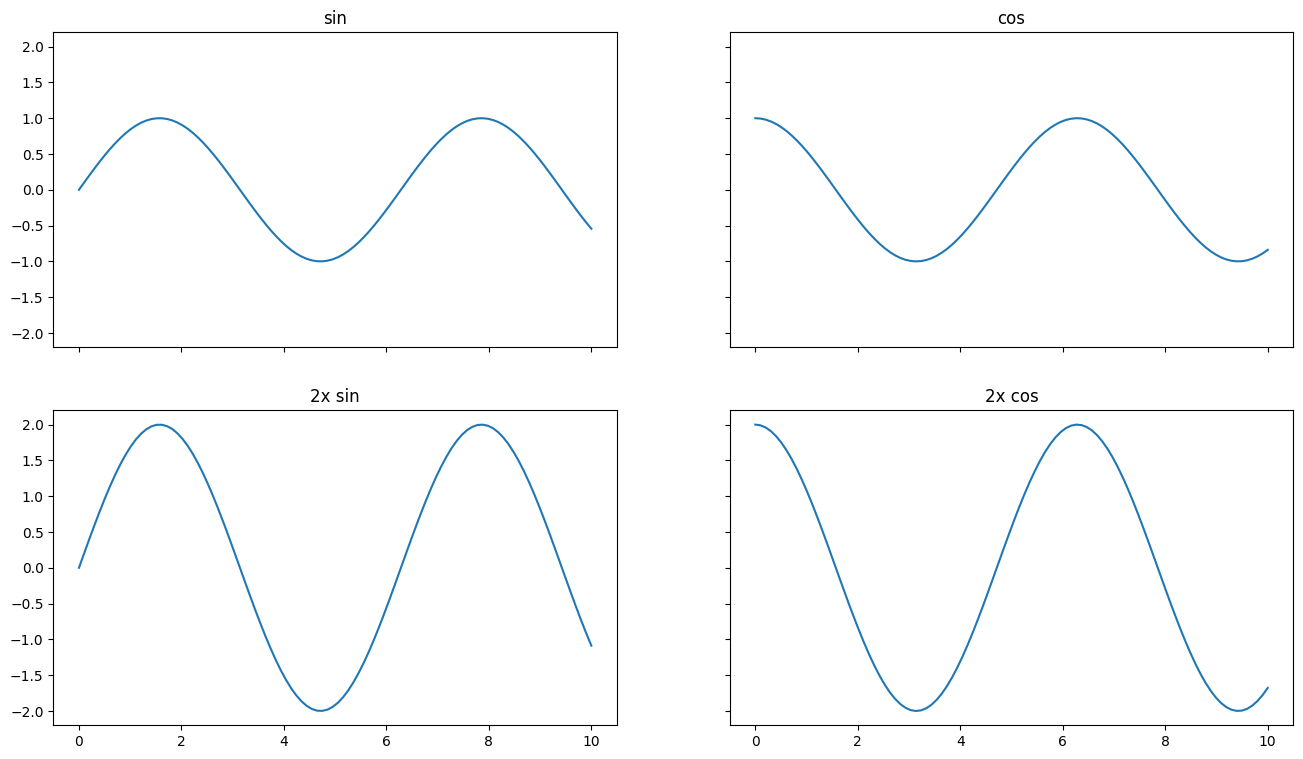

In [64]:
x = np.linspace(0,10,100)

fig,axes = plt.subplots(2,2,
    figsize=(16,9),
    sharex=True,
    sharey=True
)


axes[0,0].plot(x,np.sin(x))
axes[0,0].set_title("sin")

axes[0,1].plot(x,np.cos(x))
axes[0,1].set_title("cos")

axes[1,0].plot(x,2*np.sin(x))
axes[1,0].set_title("2x sin")

axes[1,1].plot(x,2*np.cos(x))
axes[1,1].set_title("2x cos")

plt.show()